# Proyek Analisis Data: Bike-sharing-dataset
- **Nama:** I Gede Putu Oka Pramana Putra
- **Email:** ds232b6y0749@student.devacademy.id
- **ID Dicoding:** i_putu_oka_prama2ic0

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada kondisi cuaca dan musim apa saja sistem mengalami penurunan penyewaan paling besar selama tahun 2011 hingga 2012, sehingga tim operasional bisa mengatur jadwal perawatan sepeda tanpa mengganggu ketersediaan sepeda di lapangan?
- **Pertanyaan 2:** Bagaimana perbedaan jam sibuk di hari kerja dan hari libur antara pengguna sepeda yang bekerja sehari-hari (*regitered*)dan pengguna saat berlibur (*casual*) pada periode tahun 2011 hingga 2012, agar menentukan waktu terbaik untuk memindahkan stok sepeda dari dermaga satu ke dermaga yang lain?
- **Pertanyaan 3:** Seperti apa pertumbuhan penggunaan sepeda dari tahun 2011 ke 2012 pada tiap kuartal, dan apakah kelompok pengguna yang terdaftar tumbuh lebih cepat dibandingkan pengguna sepeda biasa?

## Import Semua Packages/Library yang Digunakan

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df day_df and hour_df

In [25]:
day_df = pd.read_csv('Data/day.csv')
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [26]:
hour_df = pd.read_csv('Data/hour.csv')
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Tabel "*day_df*" berisi data harian dengan total 731 baris dan 16 kolom, yang mencakup volume penyewaan serta variabel cuaca dari tahun 2011 hingga 2012.
- Tabel "*hour_df*" berisi data yang dicatat setiap jam dengan jumlah baris sebanyak 17,379 dan kolom sebanyak 17, yang memberikan informasi tentang jam peminjaman ('hr':0-23) agar dapat dilihat bagaimana jam-jam sibuk berubah.
- Kolom "*cnt*" di kedua tabel menjatat total jumlah sepeda yang dipinjam, yang merupakan hasil dari penjumlahan antara penyewa kasual ('casual') dan penyewa terdaftar ('registered').

### Assessing Data

#### Identifying df_day and df_hour problem

In [27]:
day_df.info()

print("\nTotal missing value :", day_df.isna().sum())

print("\nJumlah duplikasi :", day_df.duplicated().sum())

print("\nMengecek sebaran statistik deskriptif :")
day_df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

Total missing value : instant       0
dteday        0
season        0
yr            0
mnth          0
holid

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [28]:
hour_df.info()

print("\nTotal missing value :", hour_df.isna().sum())

print("\nJumlah duplikasi :", hour_df.duplicated().sum())

print("\nMengecek sebaran statistik deskriptif :")
hour_df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB

Total missing value : instant       0
dteday        0
season   

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**
- Mengubah tipe data kolom "*dteday*" pada "*day_df*" dan "*hour_df*" mejadi format tanggal ('datetime').
- Mengubah kode angka pada kolom "*season*" dan "*weathersit*" pada tabel "*day_df*" menjadi label teks deskriptif.

**Insight:**
- Kedua tabel memiliki data yang lengkap tanpa baris missing value maupun duplicates.
- Kolom "*dteday*" masih berformat teks ('object'), sehingga perlu diubah ke format tanggal ('datetime').
- Kolom *season* dan *weathersit* masih berupa kode angka 1 sampai 4, sehingga perlu diubah menjadi teks agar grafik cuaca dan musim mudah dibaca.
- Nilai minimum dan maksimum pada seluruh kolom numerik berada di rentang yang wajar tanpa ada angka negatif atau anomali ekstrim.

### Cleaning Data

#### Fixing df_day and df_hour problem

In [29]:
datetime_columns = ["dteday"]

for column in datetime_columns:
    day_df[column] = pd.to_datetime(day_df[column])

season_mapping = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

day_df['season'] = day_df['season'].map(season_mapping)

weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Snow'
}

day_df['weathersit'] = day_df['weathersit'].map(weather_mapping)

day_df.info()
day_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[us]
 2   season      731 non-null    str           
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    str           
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[us](1), float64(4), int

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Spring,0,1,0,6,0,Misty/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Spring,0,1,0,0,0,Misty/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Spring,0,1,0,1,1,Clear/Partly Cloudy,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Spring,0,1,0,2,1,Clear/Partly Cloudy,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Spring,0,1,0,3,1,Clear/Partly Cloudy,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [30]:
datetime_columns = ["dteday"]

for column in datetime_columns:
    hour_df[column] = pd.to_datetime(hour_df[column])

season_mapping = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}
hour_df['season'] = hour_df['season'].map(season_mapping)

weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Snow'
}
hour_df['weathersit'] = hour_df['weathersit'].map(weather_mapping)

hour_df.info()
hour_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  str           
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  str           
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Spring,0,1,0,0,6,0,Clear/Partly Cloudy,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,Spring,0,1,1,0,6,0,Clear/Partly Cloudy,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,Spring,0,1,2,0,6,0,Clear/Partly Cloudy,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,Spring,0,1,3,0,6,0,Clear/Partly Cloudy,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,Spring,0,1,4,0,6,0,Clear/Partly Cloudy,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Kolom *dteday* pada kedua tabel telah berhasil diubah menjadi tipe "*datetime*" agar pengolahan urutan waktu berjalan semestinya.
- Nilai numerik pada kolom "*season*" dan "*weathersit*" telah dipetakan menjadi label teks deskriptif, sehingga kategori musim dan kondisi cuaca dapat dibaca dengan mudah pada grafik analisis.
- Struktur tabel dan tipe data telah diperiksa ulang dan siap digunakan untuk proses eksplorasi (EDA).

## Exploratory Data Analysis (EDA)

### Explore day_df and hour_df

In [31]:
#day_df
day_df.sample(5)
day_df.describe(include='all')

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731,731,731.000000,731.000000,731.000000,731.000000,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
unique,NaN,NaN,4,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Fall,NaN,NaN,NaN,NaN,NaN,Clear/Partly Cloudy,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,188,NaN,NaN,NaN,NaN,NaN,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,366.000000,2012-01-01 00:00:00,NaN,0.500684,6.519836,0.028728,2.997264,0.683995,NaN,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,NaN,0.000000,1.000000,0.000000,0.000000,0.000000,NaN,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,NaN,0.000000,4.000000,0.000000,1.000000,0.000000,NaN,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,NaN,1.000000,7.000000,0.000000,3.000000,1.000000,NaN,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,NaN,1.000000,10.000000,0.000000,5.000000,1.000000,NaN,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,NaN,1.000000,12.000000,1.000000,6.000000,1.000000,NaN,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [32]:
day_df.groupby(by='season').agg({
    'cnt': ['max', 'min', 'mean']
})

cnt                   
         max   min         mean
season                         
Fall    8714  1115  5644.303191
Spring  7836   431  2604.132597
Summer  8362   795  4992.331522
Winter  8555    22  4728.162921

In [33]:
day_df.groupby(by='weathersit').agg({
    'cnt': ['max', 'min', 'mean']
})

cnt                  
                      max  min         mean
weathersit                                 
Clear/Partly Cloudy  8714  431  4876.786177
Light Snow/Rain      4639   22  1803.285714
Misty/Cloudy         8362  605  4035.862348

In [34]:
day_df["quarter"] = day_df["dteday"].dt.to_period("Q")
day_df.groupby(by='quarter').agg({
    'casual': 'sum',
    'registered': 'sum',
    'cnt': 'sum'
})

,casual,registered,cnt
quarter,,,
2011Q1,22141,128308,150449
2011Q2,84008,290195,374203
2011Q3,91839,313611,405450
2011Q4,49264,263737,313001
2012Q1,49308,315448,364756
2012Q2,125985,446934,572919
2012Q3,128680,508003,636683
2012Q4,68792,406426,475218


In [35]:
#hour_df
hour_df.sample(5)
hour_df.describe(include='all')

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
unique,NaN,NaN,4,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Fall,NaN,NaN,NaN,NaN,NaN,NaN,Clear/Partly Cloudy,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,4496,NaN,NaN,NaN,NaN,NaN,NaN,11413,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,8690.0000,2012-01-02 04:08:34.552045,NaN,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,NaN,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,NaN,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,NaN,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,NaN,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,NaN,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,NaN,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,NaN,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,NaN,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,NaN,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,NaN,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [36]:
hour_df.groupby(by='hr').agg({
    'cnt': ['max', 'min', 'mean']
})

cnt                
    max min        mean
hr                     
0   283   2   53.898072
1   168   1   33.375691
2   132   1   22.869930
3    79   1   11.727403
4    28   1    6.352941
5    66   1   19.889819
6   213   1   76.044138
7   596   1  212.064649
8   839   5  359.011004
9   426  14  219.309491
10  539   8  173.668501
11  663  10  208.143054
12  776   3  253.315934
13  760  11  253.661180
14  750  12  240.949246
15  750   7  251.233196
16  783  11  311.983562
17  976  15  461.452055
18  977  23  425.510989
19  743  11  311.523352
20  567  11  226.030220
21  584   6  172.314560
22  502   9  131.335165
23  256   2   87.831044

In [37]:
hour_df.groupby(by=['workingday', 'hr']).agg({
    'casual': 'mean',
    'registered': 'mean',
    'cnt': 'mean'
})

casual  registered         cnt
workingday hr                                    
0          0    16.647826   74.152174   90.800000
           1    12.504348   57.004348   69.508696
           2    10.399123   42.771930   53.171053
           3     6.453744   19.321586   25.775330
           4     2.264317    6.000000    8.264317
           5     1.725225    6.963964    8.689189
           6     3.820961   14.921397   18.742358
           7     8.606061   34.800866   43.406926
           8    20.424242   85.229437  105.653680
           9    45.017316  126.606061  171.623377
           10   79.268398  176.640693  255.909091
           11  106.653680  208.662338  315.316017
           12  126.246753  240.012987  366.259740
           13  136.424242  236.307359  372.731602
           14  139.593074  225.051948  364.645022
           15  136.502165  222.311688  358.813853
           16  128.614719  224.112554  352.727273
           17  111.813853  211.735931  323.549784
           18   84.221739  196.834783  281.056522
           19   65.547826  166.126087  231.673913
           20   46.765217  127.973913  174.739130
           21   36.147826  105.913043  142.060870
           22   28.056522   88.004348  116.060870
           23   19.139130   66.791304   85.930435
1          0     7.149194   29.637097   36.786290
           1     3.710526   12.842105   16.552632
           2     2.137577    6.546201    8.683778
           3     0.910638    4.031915    4.942553
           4     0.765957    4.663830    5.429787
           5     1.270707   23.642424   24.913131
           6     4.318548   98.181452  102.500000
           7    12.195565  278.417339  290.612903
           8    22.264113  454.741935  477.006048
           9    24.312500  217.205645  241.518145
           10   31.205645  104.161290  135.366935
           11   37.598790  120.631048  158.229839
           12   41.358149  159.462777  200.820926
           13   42.568273  155.861446  198.429719
           14   45.869478  137.702811  183.572289
           15   46.333333  154.997992  201.331325
           16   48.344689  244.777555  293.122244
           17   56.895792  468.394790  525.290581
           18   50.451807  441.775100  492.226908
           19   41.022088  307.379518  348.401606
           20   31.369478  218.349398  249.718876
           21   24.610442  161.676707  186.287149
           22   19.572289  118.817269  138.389558
           23   13.379518   75.329317   88.708835

**Insight:**
- Selama periode **2011 hingga 2012**, penyewaan sepeda mengalami penurunan paling drastis pada musim semi (*Spring*) dengan rata-rata 2.604 unit per hari, serta saat cuaca hujan atau bersalju (*Light Snow/Rain*) yang anjlok hingga 1.803 unit per hari. Periode sepi ini merupakan waktu paling aman bagi tim operasional untuk menarik unit dan melakukan perawatan berkala tanpa khawatir kekurangan stok di lapangan.

- Pola sewa harian sepanjang tahun **2011 hingga 2012** terbagi jelas berdasarkan hari kerja dan libur. Pada hari kerja, lonjakan tajam terjadi di jam berangkat tepatnya di pukul 08.00 dan pulang kerja dari pukul 17.00 sampai 18.00 yang didominasi oleh pengguna *registered*. Sementara itu, pengguna *casual* baru ramai meminjam sepeda pada siang hingga sore hari dari pukul 12.00 sampai 15.00 di hari libur. Dengan demikian, tim lapangan dapat memindahkan stok sepeda dari satu dermaga ke dermaga lain secara leluasa sebelum pukul 07.00 pagi atau di jeda antara pukul 10.00 sampai 14.00 pada hari kerja.

- Pengguna sepeda secara konsisten tumbuh positif dari tahun **2011 hingga 2012** pada setiap kuartal, dengan kuartal ketiga (Q3) selalu mencatat puncak sewa tertinggi. Pendorong utama pertumbuhan ini berasal dari kelompok pengguna terdaftar yang volumenya melonjak drastis di tiap kuartal, menandakan bahwa layanan sepeda ini semakin dipercaya sebagai transportasi rutin harian masyarakat.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada kondisi cuaca dan musim apa saja sistem mengalami penurunan penyewaan paling besar selama periode tahun 2011 hingga 2012,sehingga tim operasional bisa mengatur jadwal perawatan sepeda tanpa mengganggu ketersediaan sepeda di lapangan?


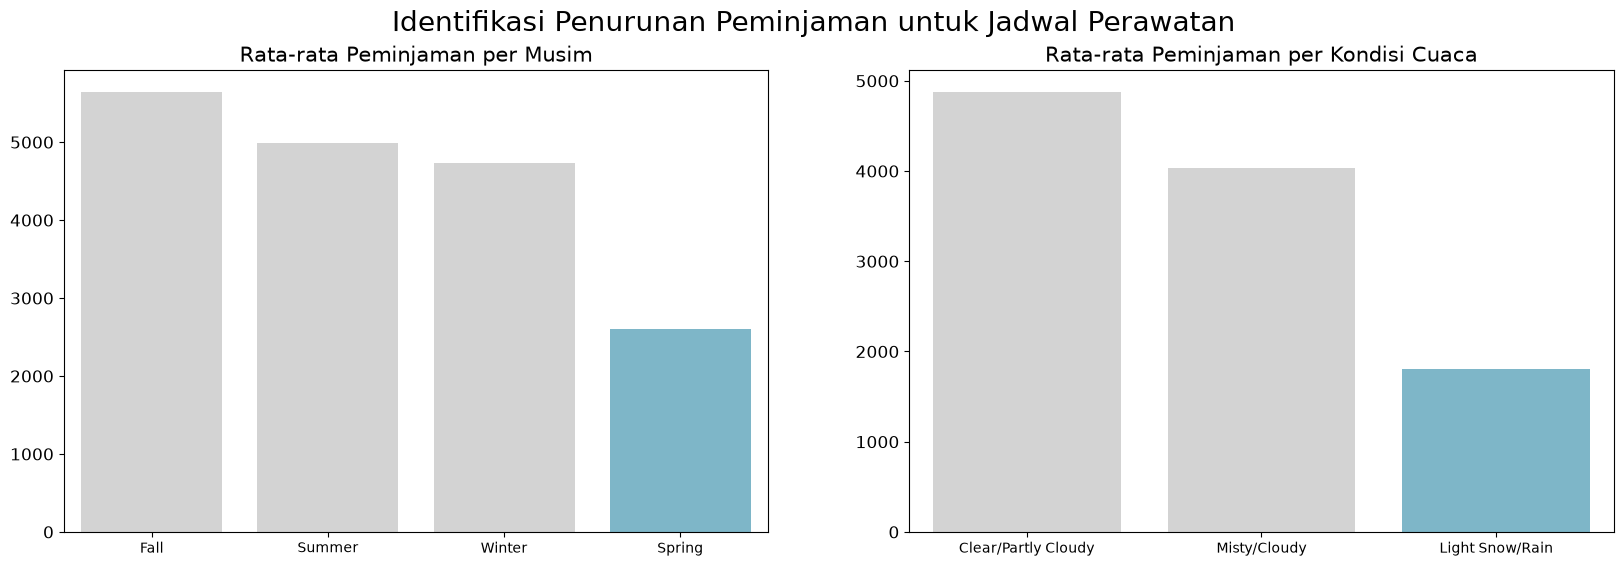

In [38]:
season_df = day_df.groupby(by='season').agg({
    'cnt': 'mean'
}).reset_index()

weather_df = day_df.groupby(by='weathersit').agg({
    'cnt': 'mean'
}).reset_index()

season_df = season_df.sort_values(by='cnt', ascending=False)
weather_df = weather_df.sort_values(by='cnt', ascending=False)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 6))

colors_season = ["#D3D3D3", "#D3D3D3", "#D3D3D3", "#72BCD4"]
colors_weather = ["#D3D3D3", "#D3D3D3", "#72BCD4"]

sns.barplot(x='season', y='cnt', data=season_df, hue="season", ax=ax[0], palette=colors_season)
ax[0].set_ylabel(None)
ax[0].set_xlabel(None)
ax[0].set_title("Rata-rata Peminjaman per Musim", loc="center", fontsize=15)
ax[0].tick_params(axis='y', labelsize=12)

sns.barplot(x='weathersit', y='cnt', data=weather_df, hue="weathersit", ax=ax[1], palette=colors_weather)
ax[1].set_ylabel(None)
ax[1].set_xlabel(None)
ax[1].set_title("Rata-rata Peminjaman per Kondisi Cuaca", loc="center", fontsize=15)
ax[1].tick_params(axis='y', labelsize=12)

plt.suptitle('Identifikasi Penurunan Peminjaman untuk Jadwal Perawatan', fontsize=20)
plt.show()

### Pertanyaan 2: Bagaimana perbedaan jam sibuk di hari kerja dan hari libur antara pengguna sepeda yang bekerja sehari-hari (*registered*) dan pengguna yang berlibur (*casual*) pada periode tahun 2011 hingga 2012, agar menentukan waktu terbaik untuk memindahkan stok sepeda dari dermaga satu ke dermaga yang lain?


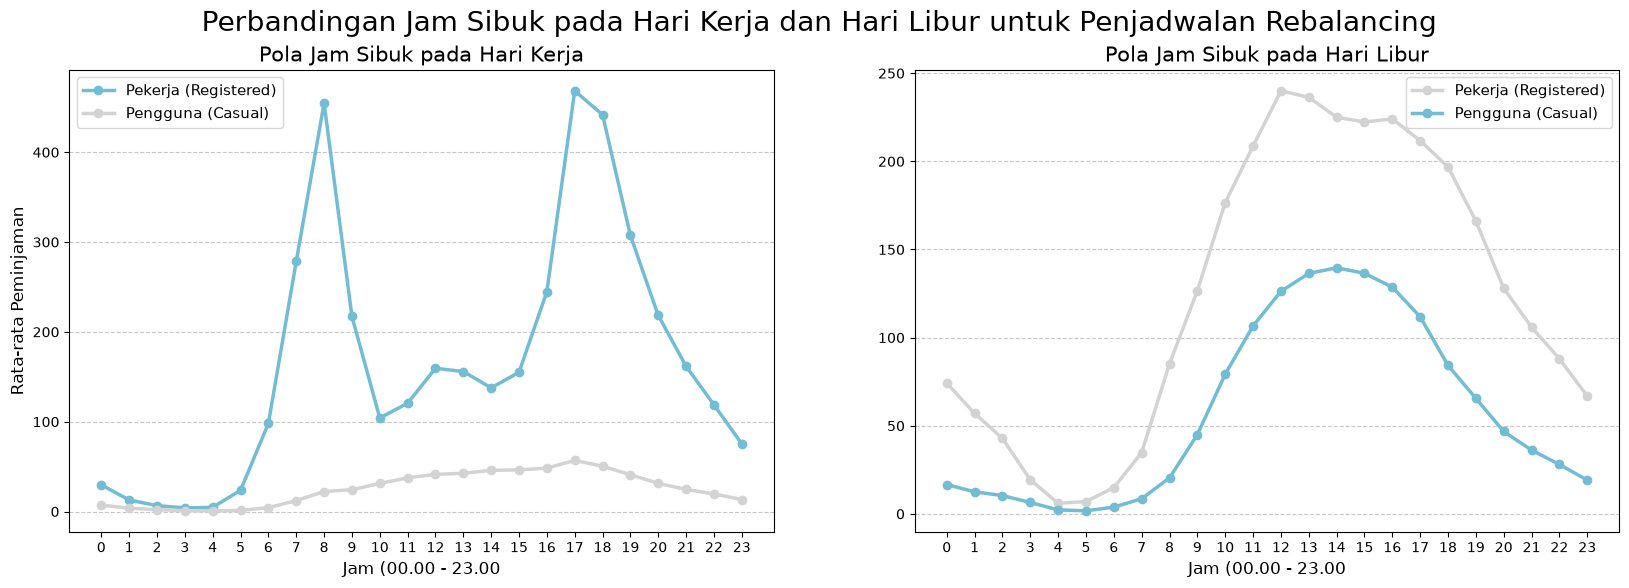

In [39]:
workingday_df = hour_df[hour_df['workingday'] == 1].groupby(by='hr')[["casual", "registered"]].mean().reset_index()
holiday_df = hour_df[hour_df['workingday'] == 0].groupby(by='hr')[["casual", "registered"]].mean().reset_index()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20,6))

ax[0].plot(workingday_df['hr'], workingday_df['registered'], label="Pekerja (Registered)", color="#72BCD4", linewidth=2.5, marker="o")
ax[0].plot(workingday_df['hr'], workingday_df['casual'], label="Pengguna (Casual)", color="#D3D3D3", linewidth=2.5, marker="o")
ax[0].set_title("Pola Jam Sibuk pada Hari Kerja", loc="center", fontsize=15)
ax[0].set_xlabel("Jam (00.00 - 23.00", fontsize=12)
ax[0].set_ylabel("Rata-rata Peminjaman", fontsize=12)
ax[0].set_xticks(range(0, 24))
ax[0].grid(axis='y', linestyle='--', alpha=0.7)
ax[0].legend(fontsize=11)

ax[1].plot(holiday_df['hr'], holiday_df['registered'], label="Pekerja (Registered)", color="#D3D3D3", linewidth=2.5, marker="o")
ax[1].plot(holiday_df['hr'], holiday_df['casual'], label="Pengguna (Casual)", color="#72BCD4", linewidth=2.5, marker="o")
ax[1].set_title("Pola Jam Sibuk pada Hari Libur", loc="center", fontsize=15)
ax[1].set_xlabel("Jam (00.00 - 23.00", fontsize=12)
ax[1].set_ylabel(None)
ax[1].set_xticks(range(0, 24))
ax[1].grid(axis='y', linestyle='--', alpha=0.7)
ax[1].legend(fontsize=11)

plt.suptitle('Perbandingan Jam Sibuk pada Hari Kerja dan Hari Libur untuk Penjadwalan Rebalancing', fontsize=20)
plt.show()

### Pertanyaan 3 : Seperti apa pertumbuhan penggunaan sepeda dari tahun 2011 ke 2012 pada tiap kuartal, dan apakah kelompok pengguna yang terdaftar tumbuh lebih cepat dibandingkan pengguna sepeda biasa?

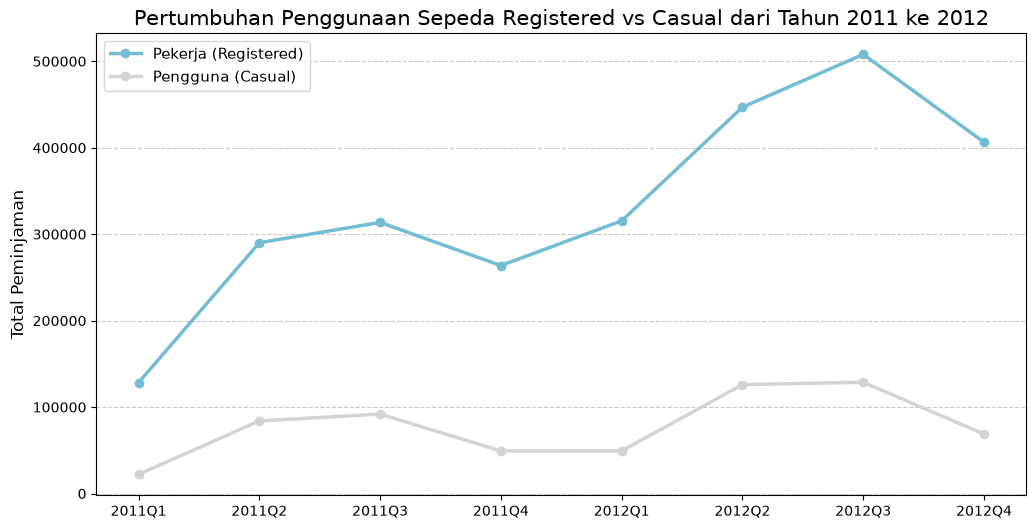

In [40]:
quarterly_df = day_df.groupby(by='quarter').agg({
    'casual': 'sum',
    'registered': 'sum'
}).reset_index()

quarterly_df["quarter"] = quarterly_df["quarter"].astype(str)

plt.figure(figsize=(12, 6))

plt.plot(quarterly_df['quarter'], quarterly_df['registered'], label="Pekerja (Registered)", color="#72BCD4", linewidth=2.5, marker="o")
plt.plot(quarterly_df['quarter'], quarterly_df['casual'], label="Pengguna (Casual)", color="#D3D3D3", linewidth=2.5, marker="o")

plt.title("Pertumbuhan Penggunaan Sepeda Registered vs Casual dari Tahun 2011 ke 2012", loc="center", fontsize=15)
plt.xlabel(None)
plt.ylabel("Total Peminjaman", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(fontsize=11)

plt.show()

**Insight:**
- Berdasarkan visualisasi dari diagram batang di atas untuk periode tahun **2011 hingga 2012**, terlihat jelas bahwa batang berwarna biru yang berada di posisi paling kanan menyoroti tingkat peminjaman paling rendah, yaitu pada musim semi (*Spring*) dan saat kondisi cuaca hujan atau bersalju (*Light Snow/Rain*). Perbedaan tinggi batang yang sangat timpang dibandingkan dengan kondisi cerah maupun musim lainnya, mengonfirmasi temuan pada tahapan eksplorasi data. Secara operasional, visualisasi ini mempertegas bahwa menarik unit sepeda untuk perawatan berkala baiknya dilakukan pada saat musim semi dan saat kondisi hujan atau bersalju karenatidak mengganggu ketersediaan sepeda di lapangan bagi pelanggan.

- Dari visualisasi diagram garis dari periode tahun **2011 hingga 2012** di atas, perbedaan prilaku pengguna pada hari kerja dan hari libur tampak sangat kontras dilihat dari bentuk kurvanya. Pada grafik hari kerja, garis pengguna registered membentuk dua puncak tajam yang menonjol pada pukul 08.00 dan 17.00 - 18.00, sementara garis pengguna casual berada rendah dan mendatar. Sebaliknya, grafik hari libur memperlihatkan kurva melengkung tunggal di mana pengguna casual meingkat signifikan sejak siang hingga sore hari dari pukul 12.00 -15.00. Bentuk pola grafik ini membenarkan bahwa waktu paling aman bagi tim lapangan untuk memindahkan stok sepeda adalah sebelum jam 07.00 pagi atau saat jeda siang pada jam 10.00 - 14.00 di hari kerja, serta sebelum pukul 10.00 pagi pada hari libur.

- Visualisasi tren garis kuartalan di atas memperlihatkan pertumbuhan volume yang terus bergerak naik dari **awal tahun 2011 hingga akhir tahun 2012**, dengan kedua garis selalu membentuk titik puncak tertinggi pada kuartal ketiga(Q3). Terlihat pula jarak renggang yang semakin melebar antara kedua garis, di mana garis pengguna registered menanjak jauh lebih curam dan mendominasi total peminjaman dibanding pengguna casual. Tampilan grafik ini memvalidasi hasil eksplorasi bahwa motor utama pertumbuhan bisnis selama dua tahun tersebut berasal dari kelompok komuter harian yang setia berlangganan.

## Analisis Lanjutan (Opsional)

demand_category   cnt                                casual   registered
                  count         mean   min   max         mean         mean
0      Low Demand   172  1859.633721    22  2999   255.808140  1603.825581
1   Medium Demand   379  4490.786280  3005  5992   803.382586  3687.403694
2     High Demand   180  7060.077778  6031  8714  1508.533333  5551.544444

/var/folders/64/_b_9z68x4yz5l20dxdvhcnf40000gn/T/ipykernel_35174/1738875817.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


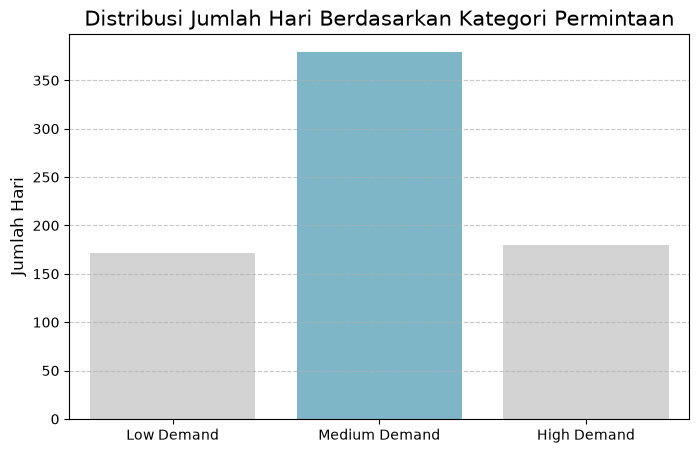

In [41]:
bins = [0, 3000, 6000, day_df["cnt"].max()]
labels = ["Low Demand", "Medium Demand", "High Demand"]

day_df["demand_category"] = pd.cut(day_df["cnt"], bins=bins, labels=labels)

demand_summary = day_df.groupby("demand_category", observed=False).agg({
    "cnt": ["count", "mean", "min", "max"],
    "casual": "mean",
    "registered": "mean"
}).reset_index()

display(demand_summary)

plt.figure(figsize=(8, 5))
colors_clusters = ["#D3D3D3", "#72BCD4", "#D3D3D3"]

sns.countplot(
    x="demand_category",
    data=day_df,
    palette=colors_clusters,
)

plt.title("Distribusi Jumlah Hari Berdasarkan Kategori Permintaan", fontsize=15)
plt.xlabel(None)
plt.ylabel("Jumlah Hari", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

**Insight:**
- Berdasarkan hasil segmentasi tingkat permintaan harian selama periode tahun **2011 hingga 2012**, operasional dikelompokkan menjadi tiga klaster, yitu ***Low Demand*** dengan sewa per hari <3000, ***Medium Demand*** dengan sewa per hari di antara 3000 - 6000, dan ***High Demand*** dengan sewa per hari >6000. Mayoritas hari operasional berada pada kategori ***Medium Demand*** dengan rata-rata peminjaman stabil di kisaran 4500 unit per harinya. Kategori ***High Demand*** menuntut kesiapan penuh seluruh armada di dermaga karena aktivitas pengguna registered maupun casual sama-sama mencapai titik puncak, sedangkan hari-hari pada kluster ***Low Demand*** menjadi acuan jadwal aman bagi tim tenis untuk menarik unit sepeda dan melakukan perawatan berkala tanpa menggangu ketersediaan layanan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Jadwal Perawatan Sepeda Berdasarkan Musim dan Cuaca Berdasarkan Data Tahun 2011 hingga 2012.\
Selama periode tahun **2011 hingga 2012**, penurunan penyewaan sepeda paling besar terjadi pada **musim semi(*Spring*)** dengan rata-rata peminjaman **2.604 per harinya**, serta pada saat kondisi cuaca **hujan atau bersalju ringan (*Light Snow/Rain*)** yang juga mengalami penurunan peminjaman dengan rata-rata mencapai **1.803 per harinya**. Kondisi ini selaras dengan hasil segmentasi permintaan harian, di mana periode tersebut masuk ke dalam kategori klaster ***Low Demand*** dengan total penyewaan berada di bawah 3000 sewa per harinya sehingga pada periode ini aman bagi tim teknis untuk melakukan penarikan unit sepeda tanpa mengganggu layanan pelanggan.

- **Conclusion pertanyaan 2:** Perbedaan Jam Sibuk dan Waktu Terbaik untuk Melakukan Pemindahan Stok berdasarkan Data Tahun 2011 hingga 2012.\
Sepanjang periode tahun **2011 hingga 2012**, pola jam sibuk terbagi sangat kontras antara hari kerja dan hari libur.
  - Hari Kerja (*Workingday* = 1) : Aktivitas didominasi oleh pengguna Registered dengan dua puncak tajam yang mendefinisikan terjadinya lonjakan penyewaan, yaitu pada jam berangkat kerja di **pukul 08.00** dengan rata-rata sewa sebanyak 455 dan pada jam pulang kerja di **pukul 17.00 - 18.00** dengan rata-rata penyewaannya sebanyak 468.
  - Hari Libur (*Woerkingday* = 0) : Aktivitas didominasi oleh pengguna casual dengan pola kurva tunggal yang mulai mengalami lonjakan peminjamaan pada **pukul 10.00 dan mencapai puncaknya pada siang hari hingga sore hari dari **pukul 12.00 - 15.00** dengan rata-rata peminjaman sebanyak 136 - 139 per jamnya.
- **Conclusion pertanyaan 3:** Pertumbuhan dalam Kuartal dari Tahun 2011 hingga 2012 dan Perbandingan Pengguna.\
Total pengguna sepeda tumbuh konsisten di setiap kuartal dari tahun 2011 ke 2012, dengan **kuartal ketiga (Q3)** selalu mencatatkan puncak volume tertinggi yang mencapai **636.683 sewa** pada 2012Q3. Kelompok pengguna registered tumbuh jauh lebih cepat dengan kenaikan tahunan sebesar **68,4%** dari yang sebelumnya hanya 995.851 menjadi 1.676.811 penyewaan, dibandingkan dengan pengguna casual yang tumbuh **50,8%** dari yang sebelumnya 247.252 menjadi 372.765 penyewaan. Data ini membuktikan bahwa penggerak utama ekspansi bisnis ini berasal dari kelompok komuter harian yang setia berlangganan.

**Rekomendasi Action Item:**
- **Penjadwalan Perawatan Armada**
  - Pusatkan jadwal servis besar dan peremajaan komponen sepeda secara menyeluruh pada rentang **musim semi (*Spring*)**.
  - Manfaatkan hari-hari dengan perkiraan cuaca buruk (**hujan atau salju ringan**) pada musim ramai untuk melakukan penarikan unit secara bergilir guna melangsungkan proses perawatan harian.

- **Optimalisasi Jadwal Pemindahan Stok**
  - **Hari Kerja :** Selesaikan pengisian stok sepeda di dermaga area perumahan dan stasiun transit sebelum pukul 07.00 pagi. Gunakan jeda siang antara pukul 10.00 - 14.00 untuk menarik tumpukan sepeda dari kawasan perkantoran kembali ke titik transit sebelum jam pulang kerja dimulai.
  - **Hari Libur :** Pastikan distribusi armada di dermaga taman, jalur rekreasi, dan kawasan wisata tuntas sebelum pukul 10.00 pagi untuk mengantisipasi lonjakan penyewa casual di siang hari.

- **Strategi Retensi Pelanggan dan Kesiapan Kuartal Puncak**
  - Pertahankan loyalitas pelanggan registered melalui program perpanjangan langganan komuter atau insentif poin perjalanan rutin, mengingat segmen ini menjadi tulang punggung pertumbuhan perusahaan.
  - Tingkatkan kapasitas armada dan kapasitas dermaga menjelang kuartal ketiga yang secara konsisten menjadi puncak volume penyewaan tahunan, sekaligus jalankan paket promo wisata akhir pekan pada periode Q2 ke Q3 untuk mendorong konversi pengguna casual menjadi anggota registered.

In [42]:
day_df.to_csv('Dashboard/day_clean.csv', index=False)
hour_df.to_csv('Dashboard/hour_clean.csv', index=False)